# PR20: preparación exploratoria de producción horaria

Se explora la producción de 2020. Los timestamps se interpretan como UTC; cada fila horaria representa el intervalo `[t, t + 1 h)`. Se calcula la potencia media en W y se estima la energía de una hora en kWh como potencia media / 1000. Esta estimación supone que las lecturas disponibles representan la hora completa.

Se exige una cobertura mínima del 99 % (3.564 de las 3.600 lecturas esperadas). Las horas con cobertura insuficiente mantienen energía ausente. Los retardos de 1, 2 y 24 horas se calculan sobre la rejilla horaria completa antes de eliminar filas incompletas. La predicción se emite al comienzo de la hora objetivo usando únicamente horas terminadas.

**Estado y límites:** todavía no hay entrenamiento ni evaluación con separación cronológica. Esta exploración horaria difiere del objetivo de potencia media en 15 minutos descrito en `docs/data_contract.md`; queda pendiente acordar resolución y objetivo con la parte de irradiación antes de integrar. El notebook carga el CSV anual completo y requiere varios GB de memoria. Las salidas existentes proceden de ejecuciones previas; esta preparación para GitHub comprueba estructura y sintaxis sin repetir la carga completa.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

print("Python del notebook:", Path.cwd())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python del notebook: c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa\notebooks
pandas: 3.0.6
NumPy: 2.5.3
scikit-learn: 1.9.1


In [3]:
from pathlib import Path

ROOT_DIR = Path.cwd()

# Si el notebook se ejecuta desde la carpeta notebooks, subimos a la raíz del proyecto
if ROOT_DIR.name.lower() == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

RAW_DIR = ROOT_DIR / "data" / "raw"

print("Raíz del proyecto:", ROOT_DIR)
print("Carpeta de datos:", RAW_DIR)
print("¿Existe?:", RAW_DIR.exists())

if RAW_DIR.exists():
    for archivo in RAW_DIR.rglob("*"):
        if archivo.is_file():
            tamaño_mb = archivo.stat().st_size / (1024 ** 2)
            print(f"{archivo.name} — {tamaño_mb:.2f} MB")

Raíz del proyecto: c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa
Carpeta de datos: c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa\data\raw
¿Existe?: True
metadata.csv — 0.00 MB
pr20_rad_2019.csv — 3.70 MB
pr20_rad_2020.csv — 35.34 MB
pr20_rad_2021.csv — 35.24 MB
pr20_rad_2022.csv — 35.20 MB
pr20_rad_2023.csv — 35.23 MB
pr20_prod_2019.csv — 190.52 MB
pr20_prod_2020.csv — 1746.00 MB
pr20_prod_2021.csv — 1739.40 MB
pr20_prod_2022.csv — 1738.23 MB
pr20_prod_2023.csv — 1711.52 MB


In [4]:
path_prueba = RAW_DIR /"PTProsumer"/ "PR20"/ "pr20_prod_2020.csv"/"pr20_prod_2020.csv"

df_muestra = pd. read_csv(path_prueba)

df_muestra.head()

,timestamp,voltage_P1,current_P1,active_power_P1,apparent_power_P1,reactive_power_P1,power_factor_P1,frequency
0,2020-01-01 00:00:00,233.6,0.247,0.0,57.9,57.9,0.018,50.1
1,2020-01-01 00:00:01,233.6,0.247,0.0,57.8,57.8,0.017,50.1
2,2020-01-01 00:00:02,233.6,0.247,0.0,57.9,57.9,0.017,50.1
3,2020-01-01 00:00:03,233.6,0.247,0.0,57.9,57.9,0.017,50.1
4,2020-01-01 00:00:04,233.6,0.247,0.0,57.8,57.8,0.017,50.1


In [5]:
df_muestra.columns.tolist()

['timestamp',
 'voltage_P1',
 'current_P1',
 'active_power_P1',
 'apparent_power_P1',
 'reactive_power_P1',
 'power_factor_P1',
 'frequency']

In [6]:
df_muestra.info()

<class 'pandas.DataFrame'>
RangeIndex: 31581875 entries, 0 to 31581874
Data columns (total 8 columns):
 #   Column             Dtype  
---  ------             -----  
 0   timestamp          str    
 1   voltage_P1         float64
 2   current_P1         float64
 3   active_power_P1    float64
 4   apparent_power_P1  float64
 5   reactive_power_P1  float64
 6   power_factor_P1    float64
 7   frequency          float64
dtypes: float64(7), str(1)
memory usage: 1.9 GB


In [7]:
df_muestra["timestamp"] = pd.to_datetime(df_muestra["timestamp"])

In [8]:
df_prod = df_muestra

In [9]:
df_prod["hora"] = df_prod["timestamp"].dt.hour
df_prod["mes"] = df_prod["timestamp"].dt.month

In [10]:
print(df_prod["hora"].head())

0    0
1    0
2    0
3    0
4    0
Name: hora, dtype: int32


In [11]:
print(df_prod["mes"].head())

0    1
1    1
2    1
3    1
4    1
Name: mes, dtype: int32


In [12]:
fechas = df_prod["timestamp"]

print("Primera fecha:", fechas.min())
print("Última fecha:", fechas.max())
print("Fechas ausentes:", fechas.isna().sum())
print("¿Están ordenadas?:", fechas.is_monotonic_increasing)
print("Fechas duplicadas:", fechas.duplicated().sum())

Primera fecha: 2020-01-01 00:00:00
Última fecha: 2020-12-31 23:59:59
Fechas ausentes: 0
¿Están ordenadas?: True
Fechas duplicadas: 0


In [13]:
intervalos = fechas.diff()

print("Intervalos más frecuentes:")
print(intervalos.value_counts().head(10))

Intervalos más frecuentes:
timestamp
0 days 00:00:01    31549755
0 days 00:00:02       31864
0 days 00:00:03          42
0 days 00:00:04          26
0 days 00:00:05          22
0 days 00:00:06          20
0 days 00:00:07          18
0 days 00:00:11          10
0 days 00:00:08           9
0 days 00:00:12           8
Name: count, dtype: int64


In [14]:
#Para conocer la cobertura anual 
esperadas = int(
    (fechas.max() - fechas.min()).total_seconds()
) + 1

faltantes = esperadas - len(fechas)

print("Registros esperados:", esperadas)
print("Registros disponibles:", len(fechas))
print("Segundos sin registro:", faltantes)
print(f"Cobertura temporal: {100 * len(fechas) / esperadas:.3f}%")
print("Mayor intervalo entre registros:", intervalos.max())

Registros esperados: 31622400
Registros disponibles: 31581875
Segundos sin registro: 40525
Cobertura temporal: 99.872%
Mayor intervalo entre registros: 0 days 00:24:43


In [15]:
potencia = df_prod["active_power_P1"]

print(potencia.describe())
print("Valores ausentes:", potencia.isna().sum())
print("Valores negativos:", (potencia < 0).sum())

count    3.158188e+07
mean     1.300923e+02
std      1.956327e+02
min      0.000000e+00
25%      0.000000e+00
50%      9.000000e-01
75%      2.149000e+02
max      7.442000e+02
Name: active_power_P1, dtype: float64
Valores ausentes: 0
Valores negativos: 0


In [16]:
cobertura_horaria = (
    df_prod.resample("1h", on="timestamp")["active_power_P1"]
    .count()
    .rename("registros")
    .to_frame()
)

# Esperamos 3.600 medidas por hora, una por segundo
cobertura_horaria["cobertura_pct"] = (
    cobertura_horaria["registros"] / 3600 * 100
)

display(cobertura_horaria["cobertura_pct"].describe())

# Las diez horas con menor cobertura
display(cobertura_horaria.nsmallest(10, "cobertura_pct"))

count    8784.000000
mean       99.871847
std         0.701383
min        58.083333
25%        99.888889
50%        99.888889
75%        99.916667
max        99.916667
Name: cobertura_pct, dtype: float64

,registros,cobertura_pct
timestamp,,
2020-03-21 01:00:00,2091,58.083333
2020-04-16 00:00:00,2879,79.972222
2020-01-02 01:00:00,2935,81.527778
2020-07-06 00:00:00,3005,83.472222
2020-09-25 00:00:00,3039,84.416667
2020-08-29 00:00:00,3083,85.638889
2020-01-27 01:00:00,3118,86.611111
2020-08-02 00:00:00,3124,86.777778
2020-12-13 01:00:00,3128,86.888889


In [17]:
cobertura_horaria["hora_valida"] = (
    cobertura_horaria["cobertura_pct"] >= 99
)

print("Horas totales:", len(cobertura_horaria))
print("Horas válidas:", cobertura_horaria["hora_valida"].sum())
print("Horas por debajo del 99 %:",
      (~cobertura_horaria["hora_valida"]).sum())

Horas totales: 8784
Horas válidas: 8762
Horas por debajo del 99 %: 22


In [18]:
rutas_metadata = [
    ruta
    for ruta in RAW_DIR.rglob("metadata.csv")
    if ruta.is_file()
]

for ruta in rutas_metadata:
    print(ruta)

c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa\data\raw\PTProsumer\metadata.csv


In [19]:
metadata = pd.read_csv(rutas_metadata[0])
display(metadata)

,ID,Type,Phases_Cons,Phases_Prod,Peak_Power_Cons,Peak_Power_Prod,Collection_Start,Collection _End,Complete_Net-Load,Complete_Production
0,PR_01,Office,1,1,10.35,1.50,29/03/2018,21/02/2022,85.13,85.13
1,PR_02,House,3,1,10.35,2.70,01/05/2018,21/02/2022,94.94,95.04
2,PR_03,Restaurant,3,3,20.70,3.92,25/05/2018,20/05/2022,96.75,97.46
3,PR_04,House,1,1,6.90,1.25,29/05/2018,24/01/2020,99.20,99.28
4,PR_05,Apartment,1,1,6.90,0.50,06/06/2018,13/03/2023,95.53,95.55
5,PR_06,House,1,1,3.45,0.75,09/06/2018,21/02/2022,98.63,99.61
6,PR_07,House,1,1,6.90,0.39,19/06/2018,27/03/2021,99.40,99.40
7,PR_08,House,1,1,6.90,1.50,20/06/2018,20/09/2018,98.20,98.20
8,PR_09,House,1,1,6.90,1.50,23/06/2018,31/12/2023,87.69,87.68
9,PR_10,House,1,1,10.35,0.50,28/06/2018,24/06/2020,97.88,97.88


In [31]:
df_muestra["timestamp"] = pd.to_datetime(
    df_muestra["timestamp"],
    utc=True,
)

In [32]:
df_horario = (
    df_prod.resample("1h", on="timestamp", closed="left", label="left")
    ["active_power_P1"]
    .agg(potencia_media_w="mean", registros="count")
)

df_horario["cobertura_pct"] = df_horario["registros"] / 3600 * 100
df_horario["hora_valida"] = df_horario["cobertura_pct"] >= 99

In [33]:
df_horario["energia_estimada_kwh"] = (
    df_horario["potencia_media_w"] / 1000
).where(df_horario["hora_valida"])

display(df_horario.head())

,potencia_media_w,registros,cobertura_pct,hora_valida,energia_estimada_kwh
timestamp,,,,,
2020-01-01 00:00:00+00:00,0.0,3596,99.888889,True,0.0
2020-01-01 01:00:00+00:00,0.0,3596,99.888889,True,0.0
2020-01-01 02:00:00+00:00,0.0,3596,99.888889,True,0.0
2020-01-01 03:00:00+00:00,0.0,3597,99.916667,True,0.0
2020-01-01 04:00:00+00:00,0.0,3596,99.888889,True,0.0


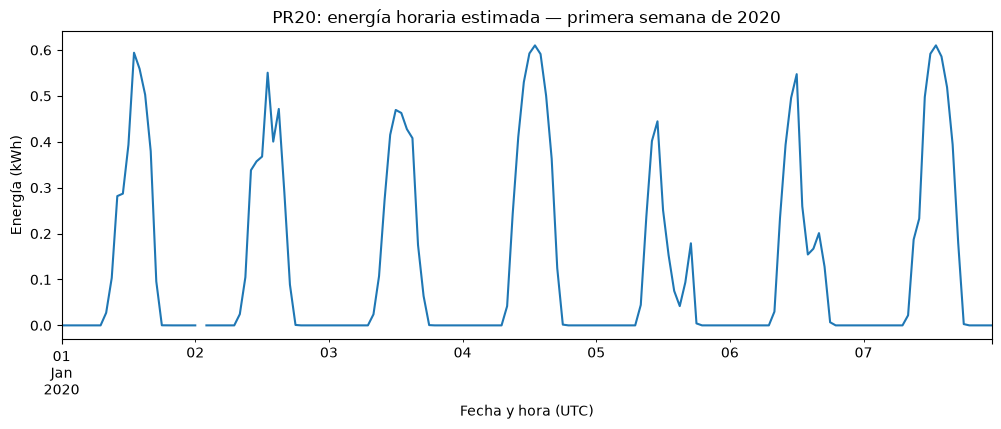

In [34]:
df_horario.loc[
    "2020-01-01":"2020-01-07", "energia_estimada_kwh"
].plot(
    figsize=(12, 4),
    title="PR20: energía horaria estimada — primera semana de 2020",
    xlabel="Fecha y hora (UTC)",
    ylabel="Energía (kWh)"
)

plt.show()

In [35]:
print(df_horario["energia_estimada_kwh"].describe())
print(
    "Horas sin energía estimada:",
    df_horario["energia_estimada_kwh"].isna().sum()
)

count    8762.000000
mean        0.130383
std         0.187520
min         0.000000
25%         0.000000
50%         0.003469
75%         0.244001
max         0.645599
Name: energia_estimada_kwh, dtype: float64
Horas sin energía estimada: 22


In [36]:
df_modelo = pd.DataFrame(index=df_horario.index)

energia = df_horario["energia_estimada_kwh"]

# Objetivo: energía de la hora que comienza en el instante de predicción
df_modelo["objetivo_kwh"] = energia

# Entradas: energía de horas que ya han terminado
df_modelo["energia_anterior_1h"] = energia.shift(1)
df_modelo["energia_anterior_2h"] = energia.shift(2)
df_modelo["energia_anterior_24h"] = energia.shift(24)

display(df_modelo.loc["2020-01-02 09:00":"2020-01-02 12:00"])

,objetivo_kwh,energia_anterior_1h,energia_anterior_2h,energia_anterior_24h
timestamp,,,,
2020-01-02 09:00:00+00:00,0.105030,0.024411,0.000000,0.103352
2020-01-02 10:00:00+00:00,0.338131,0.105030,0.024411,0.281706
2020-01-02 11:00:00+00:00,0.357346,0.338131,0.105030,0.287076
2020-01-02 12:00:00+00:00,0.367831,0.357346,0.338131,0.393518


In [37]:
df_modelo["hora"] = df_modelo.index.hour
df_modelo["mes"] = df_modelo.index.month

In [38]:
df_modelo.isna().sum()

objetivo_kwh            22
energia_anterior_1h     23
energia_anterior_2h     24
energia_anterior_24h    46
hora                     0
mes                      0
dtype: int64

In [39]:
df_modelo_limpio = df_modelo.dropna().copy()

print("Filas originales:", len(df_modelo))
print("Filas completas:", len(df_modelo_limpio))

Filas originales: 8784
Filas completas: 8680


In [40]:
for nombre, tabla in {
    "Producción original": df_prod,
    "Producción horaria": df_horario,
    "Datos del modelo": df_modelo_limpio,
}.items():
    memoria_mb = tabla.memory_usage(deep=True).sum() / 1024**2
    print(f"{nombre}: {memoria_mb:,.2f} MB")

Producción original: 2,168.56 MB
Producción horaria: 0.60 MB
Datos del modelo: 0.40 MB


## Primer experimento: predicción de energía de la próxima hora

Cada fila representa una predicción emitida en el instante `t`,
al comienzo de una hora, con fechas en UTC.

El objetivo es estimar la energía fotovoltaica producida durante
el intervalo `[t, t + 1 h)`, expresada en kWh.

Variables de entrada:
- Energía de la última hora terminada: `[t - 1 h, t)`.
- Energía de la hora anterior a esa: `[t - 2 h, t - 1 h)`.
- Energía de la misma hora del día anterior:
  `[t - 24 h, t - 23 h)`.
- Hora y mes del intervalo objetivo.

Los retardos se calculan sobre la rejilla horaria completa antes
de eliminar las filas con valores ausentes.

In [55]:
df_train = df_modelo_limpio.loc[
    df_modelo_limpio.index < "2020-09-01"
].copy()

df_val = df_modelo_limpio.loc[
    (df_modelo_limpio.index >= "2020-09-01")
    & (df_modelo_limpio.index < "2020-11-01")
].copy()

df_test = df_modelo_limpio.loc[
    df_modelo_limpio.index >= "2020-11-01"
].copy()

for nombre, tabla in {
    "Entrenamiento": df_train,
    "Validación": df_val,
    "Prueba": df_test,
}.items():
    print(
        f"{nombre}: {len(tabla)} filas | "
        f"{tabla.index.min()} → {tabla.index.max()}"
    )

Entrenamiento: 5780 filas | 2020-01-02 00:00:00+00:00 → 2020-08-31 23:00:00+00:00
Validación: 1453 filas | 2020-09-01 00:00:00+00:00 → 2020-10-31 23:00:00+00:00
Prueba: 1447 filas | 2020-11-01 00:00:00+00:00 → 2020-12-31 23:00:00+00:00


In [56]:
variables_entrada = [
"energia_anterior_1h",
"energia_anterior_2h",
"energia_anterior_24h",
"hora",
"mes",
]

variable_objetivo = "objetivo_kwh"

X_train = df_train[variables_entrada].copy()
y_train = df_train[variable_objetivo].copy()

X_val = df_val[variables_entrada].copy()
y_val = df_val[variable_objetivo].copy()

In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

pred_persistencia = X_val["energia_anterior_1h"]
pred_persistencia_diaria = X_val["energia_anterior_24h"]

resultados_referencia = []

for nombre, prediccion in {
    "Persistencia": pred_persistencia,
    "Persistencia diaria": pred_persistencia_diaria,
}.items():
    resultados_referencia.append({
        "modelo": nombre,
        "MAE_kwh": mean_absolute_error(y_val, prediccion),
        "RMSE_kwh": np.sqrt(mean_squared_error(y_val, prediccion)),
    })

df_resultados = pd.DataFrame(resultados_referencia).set_index("modelo")

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095


In [58]:
from sklearn.linear_model import LinearRegression

modelo_lineal = LinearRegression()

modelo_lineal.fit(X_train, y_train)

pred_lineal = modelo_lineal.predict(X_val)

In [59]:
df_resultados.loc["Regresión lineal", ["MAE_kwh", "RMSE_kwh"]] = [
    mean_absolute_error(y_val, pred_lineal),
    np.sqrt(mean_squared_error(y_val, pred_lineal)),
]

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095
Regresión lineal,0.039103,0.064376


In [60]:
coeficientes = pd.DataFrame({
    "variable": X_train.columns,
    "coeficiente": modelo_lineal.coef_,
})

display(coeficientes)
print(f"Intercepto: {modelo_lineal.intercept_:.6f} kWh") #Para 6 decimales

,variable,coeficiente
0,energia_anterior_1h,1.065893
1,energia_anterior_2h,-0.421366
2,energia_anterior_24h,0.286807
3,hora,-0.000381
4,mes,0.000120


Intercepto: 0.013347 kWh


In [61]:
print(f"Intercepto: {modelo_lineal.intercept_:.6f} kWh")

print("Predicciones negativas:", (pred_lineal < 0).sum())
print(f"Predicción mínima: {pred_lineal.min():.6f} kWh")
print(f"Predicción máxima: {pred_lineal.max():.6f} kWh")

Intercepto: 0.013347 kWh
Predicciones negativas: 88
Predicción mínima: -0.071307 kWh
Predicción máxima: 0.662041 kWh


Debido a que tenemos 88 predicciones negativas (alrededor de 6.1%), entonces sustituimos las predicciones negativas por cero.

In [62]:
pred_lineal_no_negativa = np.maximum(pred_lineal, 0)

df_resultados.loc[
    "Regresión lineal (mínimo cero)",
    ["MAE_kwh", "RMSE_kwh"],
] = [
    mean_absolute_error(y_val, pred_lineal_no_negativa),
    np.sqrt(mean_squared_error(y_val, pred_lineal_no_negativa)),
]

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095
Regresión lineal,0.039103,0.064376
Regresión lineal (mínimo cero),0.037648,0.063816


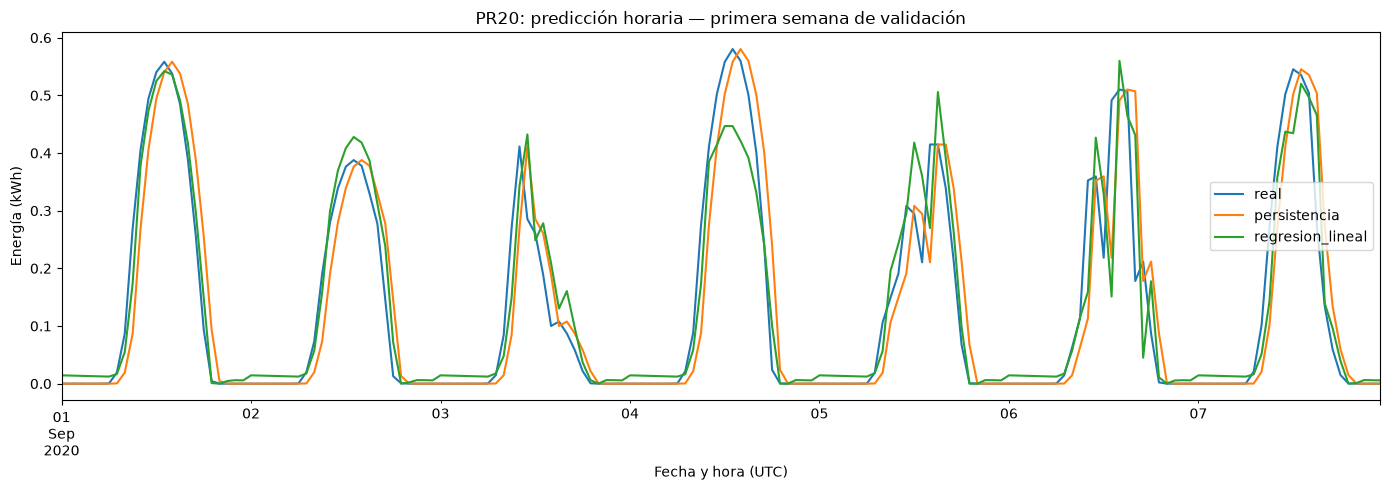

In [63]:
df_predicciones_val = pd.DataFrame({
    "real": y_val,
    "persistencia": pred_persistencia,
    "regresion_lineal": pred_lineal_no_negativa,
})

df_predicciones_val.loc["2020-09-01":"2020-09-07"].plot(
    figsize=(14, 5),
    title="PR20: predicción horaria — primera semana de validación",
    xlabel="Fecha y hora (UTC)",
    ylabel="Energía (kWh)",
)

plt.tight_layout()
plt.show()

In [64]:
df_predicciones_val["error_lineal"] = (
    df_predicciones_val["regresion_lineal"]
    - df_predicciones_val["real"]
)

df_predicciones_val["error_absoluto_lineal"] = (
    df_predicciones_val["error_lineal"].abs()
)

print(
    "Error medio con signo:",
    df_predicciones_val["error_lineal"].mean(),
    "kWh",
)

display(
    df_predicciones_val.nlargest(
        10, "error_absoluto_lineal"
    )
)

Error medio con signo: 0.0025853408741505395 kWh


,real,persistencia,regresion_lineal,error_lineal,error_absoluto_lineal
timestamp,,,,,
2020-09-27 13:00:00+00:00,0.524060,0.327155,0.183576,-0.340483,0.340483
2020-09-06 13:00:00+00:00,0.491421,0.218347,0.151092,-0.340328,0.340328
2020-10-06 14:00:00+00:00,0.336864,0.608923,0.662041,0.325178,0.325178
2020-10-27 12:00:00+00:00,0.267821,0.506810,0.588990,0.321169,0.321169
2020-10-28 15:00:00+00:00,0.528722,0.260371,0.209469,-0.319253,0.319253
2020-10-14 14:00:00+00:00,0.129363,0.464978,0.441242,0.311880,0.311880
2020-10-28 16:00:00+00:00,0.170509,0.528722,0.477316,0.306807,0.306807
2020-10-03 12:00:00+00:00,0.583279,0.312600,0.295256,-0.288023,0.288023
2020-10-26 13:00:00+00:00,0.243445,0.510779,0.520755,0.277310,0.277310


In [65]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)

modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_val)

In [66]:
df_resultados.loc["Random Forest", ["MAE_kwh", "RMSE_kwh"]] = [
    mean_absolute_error(y_val, pred_rf),
    np.sqrt(mean_squared_error(y_val, pred_rf)),
]

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095
Regresión lineal,0.039103,0.064376
Regresión lineal (mínimo cero),0.037648,0.063816
Random Forest,0.027765,0.055694


In [67]:
pred_rf_train = modelo_rf.predict(X_train)

comparacion_rf = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación"],
    "MAE_kwh": [
        mean_absolute_error(y_train, pred_rf_train),
        mean_absolute_error(y_val, pred_rf),
    ],
    "RMSE_kwh": [
        np.sqrt(mean_squared_error(y_train, pred_rf_train)),
        np.sqrt(mean_squared_error(y_val, pred_rf)),
    ],
}).set_index("conjunto")

display(comparacion_rf)

,MAE_kwh,RMSE_kwh
conjunto,,
Entrenamiento,0.015587,0.033925
Validación,0.027765,0.055694


In [68]:
resultados_profundidad = []

for profundidad in [5, 10, None]:
    modelo = RandomForestRegressor(
        n_estimators=200,
        max_depth=profundidad,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados_profundidad.append({
        "profundidad": (
            str(profundidad) if profundidad is not None else "Sin límite"
        ),
        "MAE_train_kwh": mean_absolute_error(y_train, pred_train),
        "MAE_val_kwh": mean_absolute_error(y_val, pred_val),
        "RMSE_val_kwh": np.sqrt(mean_squared_error(y_val, pred_val)),
    })

display(pd.DataFrame(resultados_profundidad))

,profundidad,MAE_train_kwh,MAE_val_kwh,RMSE_val_kwh
0,5,0.022856,0.028771,0.056378
1,10,0.016418,0.027508,0.055330
2,Sin límite,0.015587,0.027765,0.055694


Preparamos el GridSearch, evaluando primero las particiones temporales que utilizará. 

In [69]:
from sklearn.model_selection import TimeSeriesSplit

cv_temporal = TimeSeriesSplit(n_splits=3)

for numero, (indices_train, indices_val) in enumerate(
    cv_temporal.split(X_train),
    start=1,
):
    fechas_train = X_train.index[indices_train]
    fechas_val = X_train.index[indices_val]

    print(f"Partición {numero}")
    print(
        f"  Entrenamiento: {fechas_train.min()} → {fechas_train.max()}"
    )
    print(
        f"  Validación interna: {fechas_val.min()} → {fechas_val.max()}"
    )

Partición 1
  Entrenamiento: 2020-01-02 00:00:00+00:00 → 2020-03-02 16:00:00+00:00
  Validación interna: 2020-03-02 17:00:00+00:00 → 2020-05-02 05:00:00+00:00
Partición 2
  Entrenamiento: 2020-01-02 00:00:00+00:00 → 2020-05-02 05:00:00+00:00
  Validación interna: 2020-05-02 06:00:00+00:00 → 2020-07-02 03:00:00+00:00
Partición 3
  Entrenamiento: 2020-01-02 00:00:00+00:00 → 2020-07-02 03:00:00+00:00
  Validación interna: 2020-07-02 04:00:00+00:00 → 2020-08-31 23:00:00+00:00


In [ ]:
from sklearn.model_selection import GridSearchCV

parametros_rf = {
    "max_depth": [5, 10, 20, None],
    "min_samples_leaf": [1, 5, 15, 23]
}

busqueda_rf = GridSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    ),
    param_grid=parametros_rf,
    scoring="neg_mean_absolute_error",
    cv=cv_temporal,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)

busqueda_rf.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the

In [71]:
print("Mejores parámetros:", busqueda_rf.best_params_)

print(
    f"MAE medio de validación interna: "
    f"{-busqueda_rf.best_score_:.6f} kWh"
)

Mejores parámetros: {'max_depth': 10, 'min_samples_leaf': 5}
MAE medio de validación interna: 0.024339 kWh


In [72]:
#Comparamos las configuraciones

resultados_grid = pd.DataFrame(busqueda_rf.cv_results_)

resultados_grid["MAE_train_kwh"] = (
    -resultados_grid["mean_train_score"]
)

resultados_grid["MAE_cv_kwh"] = (
    -resultados_grid["mean_test_score"]
)

display(
    resultados_grid.sort_values("rank_test_score")[
        [
            "param_max_depth",
            "param_min_samples_leaf",
            "MAE_train_kwh",
            "MAE_cv_kwh",
            "std_test_score",
            "rank_test_score",
        ]
    ]
)

,param_max_depth,param_min_samples_leaf,MAE_train_kwh,MAE_cv_kwh,std_test_score,rank_test_score
5,10,5,0.018470,0.024339,0.005920,1
9,20,5,0.018163,0.024431,0.005853,2
13,None,5,0.018163,0.024431,0.005853,2
6,10,15,0.023064,0.025015,0.006304,4
10,20,15,0.023063,0.025021,0.006297,5
14,None,15,0.023063,0.025021,0.006297,5
1,5,5,0.024143,0.025258,0.005657,7
0,5,1,0.023977,0.025405,0.005814,8
4,10,1,0.013368,0.025483,0.006824,9
2,5,15,0.024857,0.025617,0.006027,10


In [73]:
modelo_rf_optimizado = busqueda_rf.best_estimator_

pred_rf_optimizado = modelo_rf_optimizado.predict(X_val)

df_resultados.loc[
    "Random Forest (GridSearch)",
    ["MAE_kwh", "RMSE_kwh"],
] = [
    mean_absolute_error(y_val, pred_rf_optimizado),
    np.sqrt(mean_squared_error(y_val, pred_rf_optimizado)),
]

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095
Regresión lineal,0.039103,0.064376
Regresión lineal (mínimo cero),0.037648,0.063816
Random Forest,0.027765,0.055694
Random Forest (GridSearch),0.027508,0.055330


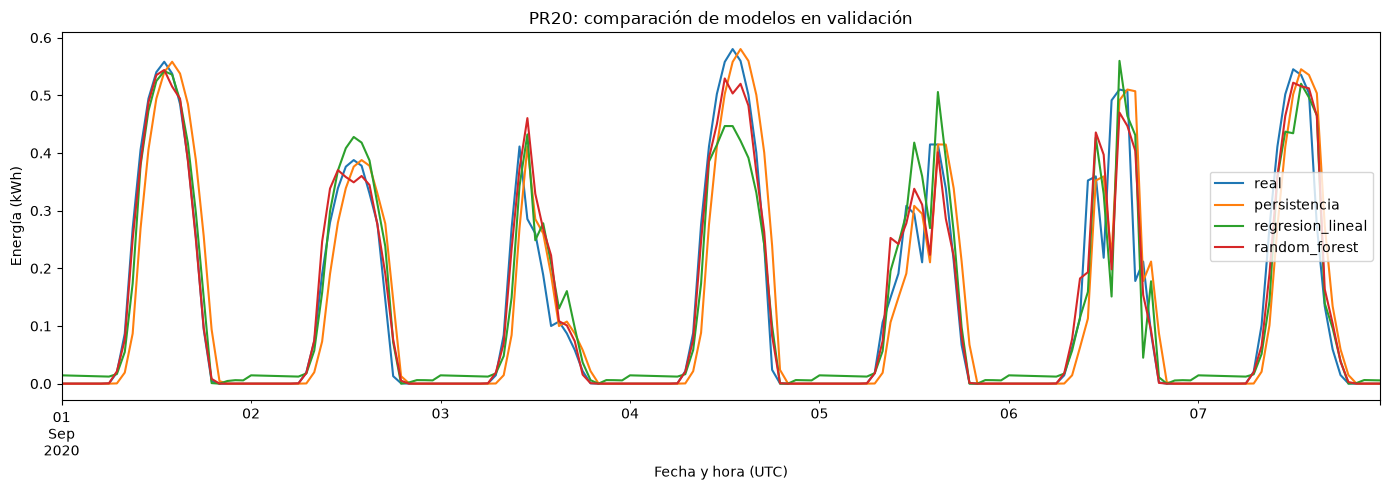

In [74]:
df_predicciones_val["random_forest"] = pred_rf_optimizado

df_predicciones_val.loc[
    "2020-09-01":"2020-09-07",
    ["real", "persistencia", "regresion_lineal", "random_forest"],
].plot(
    figsize=(14, 5),
    title="PR20: comparación de modelos en validación",
    xlabel="Fecha y hora (UTC)",
    ylabel="Energía (kWh)",
)

plt.tight_layout()
plt.show()

In [75]:
parametros_rf_refinado = {
    "max_depth": [8, 10, 12],
    "min_samples_leaf": [3, 5, 8],
    "max_features": [0.6, 1.0],
}

busqueda_rf_refinada = GridSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    ),
    param_grid=parametros_rf_refinado,
    scoring="neg_mean_absolute_error",
    cv=cv_temporal,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)

busqueda_rf_refinada.fit(X_train, y_train)

print("Mejores parámetros:", busqueda_rf_refinada.best_params_)
print(
    f"MAE medio de validación interna: "
    f"{-busqueda_rf_refinada.best_score_:.6f} kWh"
)


Fitting 3 folds for each of 18 candidates, totalling 54 fits
Mejores parámetros: {'max_depth': 12, 'max_features': 0.6, 'min_samples_leaf': 5}
MAE medio de validación interna: 0.024098 kWh


In [76]:
modelo_rf_refinado = busqueda_rf_refinada.best_estimator_

pred_rf_refinado = modelo_rf_refinado.predict(X_val)

df_resultados.loc[
    "Random Forest (GridSearch refinado)",
    ["MAE_kwh", "RMSE_kwh"],
] = [
    mean_absolute_error(y_val, pred_rf_refinado),
    np.sqrt(mean_squared_error(y_val, pred_rf_refinado)),
]

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095
Regresión lineal,0.039103,0.064376
Regresión lineal (mínimo cero),0.037648,0.063816
Random Forest,0.027765,0.055694
Random Forest (GridSearch),0.027508,0.055330
Random Forest (GridSearch refinado),0.027597,0.055067


| Configuración | MAE | RMSE |
|---|---:|---:|
| Primera búsqueda | **27,508 Wh** | 55,330 Wh |
| Búsqueda refinada | 27,597 Wh | **55,067 Wh** |

In [77]:
from sklearn.ensemble import GradientBoostingRegressor

modelo_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42,
)

modelo_gb.fit(X_train, y_train)

pred_gb_original = modelo_gb.predict(X_val)
pred_gb = np.maximum(pred_gb_original, 0)

In [78]:
df_resultados.loc["Gradient Boosting", ["MAE_kwh", "RMSE_kwh"]] = [
    mean_absolute_error(y_val, pred_gb),
    np.sqrt(mean_squared_error(y_val, pred_gb)),
]

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095
Regresión lineal,0.039103,0.064376
Regresión lineal (mínimo cero),0.037648,0.063816
Random Forest,0.027765,0.055694
Random Forest (GridSearch),0.027508,0.055330
Random Forest (GridSearch refinado),0.027597,0.055067
Gradient Boosting,0.027418,0.054515


In [79]:
pred_gb_train = np.maximum(
    modelo_gb.predict(X_train),
    0,
)

comparacion_gb = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación"],
    "MAE_kwh": [
        mean_absolute_error(y_train, pred_gb_train),
        mean_absolute_error(y_val, pred_gb),
    ],
    "RMSE_kwh": [
        np.sqrt(mean_squared_error(y_train, pred_gb_train)),
        np.sqrt(mean_squared_error(y_val, pred_gb)),
    ],
}).set_index("conjunto")

display(comparacion_gb)

,MAE_kwh,RMSE_kwh
conjunto,,
Entrenamiento,0.020951,0.042409
Validación,0.027418,0.054515


In [80]:
from sklearn.metrics import make_scorer

# Evaluamos la misma predicción no negativa que usaremos después
def mae_no_negativo(y_real, y_pred):
    return mean_absolute_error(y_real, np.maximum(y_pred, 0))

scorer_mae_no_negativo = make_scorer(
    mae_no_negativo,
    greater_is_better=False,
)

parametros_gb = {
    "n_estimators": [100, 200, 400],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
}

busqueda_gb = GridSearchCV(
    estimator=GradientBoostingRegressor(
        min_samples_leaf=5,
        random_state=42,
    ),
    param_grid=parametros_gb,
    scoring=scorer_mae_no_negativo,
    cv=cv_temporal,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)

busqueda_gb.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(m...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`

In [81]:
print("Mejores parámetros:", busqueda_gb.best_params_)

print(
    f"MAE medio de validación interna: "
    f"{-busqueda_gb.best_score_:.6f} kWh"
)

Mejores parámetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
MAE medio de validación interna: 0.025475 kWh


In [82]:
modelo_gb_optimizado = busqueda_gb.best_estimator_

pred_gb_optimizado = np.maximum(
    modelo_gb_optimizado.predict(X_val),
    0,
)

df_resultados.loc[
    "Gradient Boosting (GridSearch)",
    ["MAE_kwh", "RMSE_kwh"],
] = [
    mean_absolute_error(y_val, pred_gb_optimizado),
    np.sqrt(mean_squared_error(y_val, pred_gb_optimizado)),
]

display(df_resultados)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.047373,0.082493
Persistencia diaria,0.051343,0.108095
Regresión lineal,0.039103,0.064376
Regresión lineal (mínimo cero),0.037648,0.063816
Random Forest,0.027765,0.055694
Random Forest (GridSearch),0.027508,0.055330
Random Forest (GridSearch refinado),0.027597,0.055067
Gradient Boosting,0.027418,0.054515
Gradient Boosting (GridSearch),0.028592,0.055082


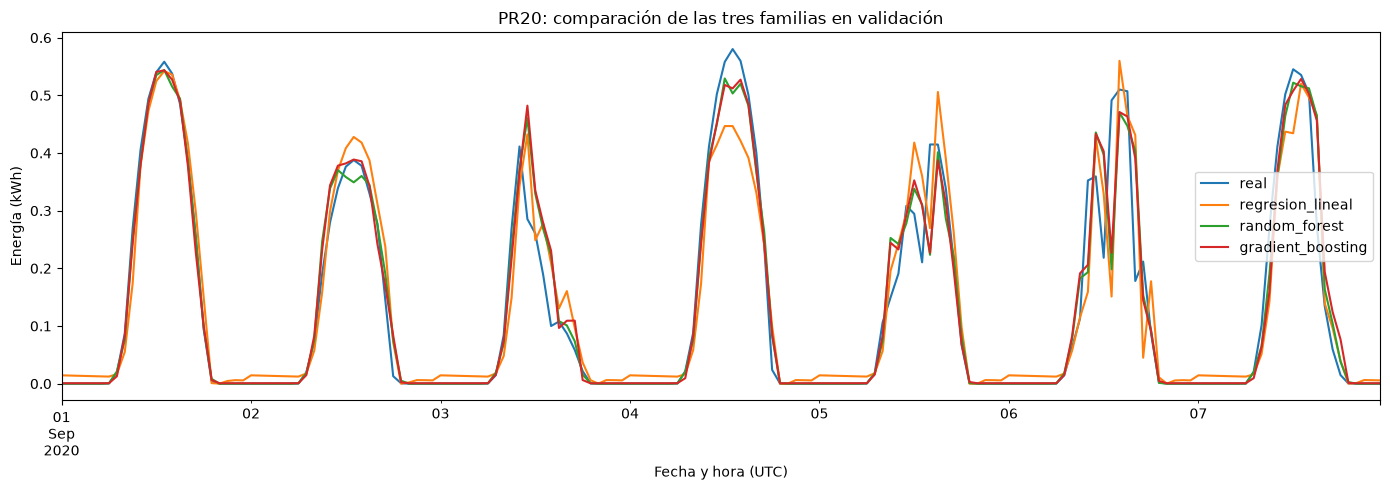

In [83]:
df_predicciones_val["gradient_boosting"] = pred_gb

df_predicciones_val.loc[
    "2020-09-01":"2020-09-07",
    ["real", "regresion_lineal", "random_forest", "gradient_boosting"],
].plot(
    figsize=(14, 5),
    title="PR20: comparación de las tres familias en validación",
    xlabel="Fecha y hora (UTC)",
    ylabel="Energía (kWh)",
)

plt.tight_layout()
plt.show()

In [84]:
modelos_cuantiles = {}
predicciones_cuantiles = pd.DataFrame(index=X_val.index)

for cuantil in [0.10, 0.50, 0.90]:
    modelo = GradientBoostingRegressor(
        loss="quantile",
        alpha=cuantil,
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        random_state=42,
    )

    modelo.fit(X_train, y_train)

    modelos_cuantiles[cuantil] = modelo

    predicciones_cuantiles[f"q{int(cuantil * 100)}"] = np.maximum(
        modelo.predict(X_val),
        0,
    )

display(predicciones_cuantiles.head())

,q10,q50,q90
timestamp,,,
2020-09-01 00:00:00+00:00,0.0,3.579568e-07,0.000026
2020-09-01 01:00:00+00:00,0.0,3.579568e-07,0.000031
2020-09-01 02:00:00+00:00,0.0,3.579568e-07,0.000030
2020-09-01 03:00:00+00:00,0.0,3.579568e-07,0.000030
2020-09-01 04:00:00+00:00,0.0,3.579568e-07,0.000030


In [85]:
cruces = (
    (predicciones_cuantiles["q10"] > predicciones_cuantiles["q50"])
    | (predicciones_cuantiles["q50"] > predicciones_cuantiles["q90"])
)

print("Horas evaluadas:", len(predicciones_cuantiles))
print("Horas con cuantiles cruzados:", cruces.sum())
print(f"Porcentaje de cruces: {cruces.mean():.2%}")

Horas evaluadas: 1453
Horas con cuantiles cruzados: 36
Porcentaje de cruces: 2.48%


In [86]:
tabla_cuantiles = predicciones_cuantiles.copy()
tabla_cuantiles["real"] = y_val

display(
    tabla_cuantiles.loc[
        "2020-09-01 09:00":"2020-09-01 16:00"
    ]
)

,q10,q50,q90,real
timestamp,,,,
2020-09-01 09:00:00+00:00,0.0,0.220364,0.271925,0.269177
2020-09-01 10:00:00+00:00,0.0,0.359280,0.430523,0.405898
2020-09-01 11:00:00+00:00,0.0,0.483492,0.513906,0.494378
2020-09-01 12:00:00+00:00,0.0,0.554152,0.560069,0.540274
2020-09-01 13:00:00+00:00,0.0,0.554008,0.569926,0.558319
2020-09-01 14:00:00+00:00,0.0,0.540050,0.550793,0.537806
2020-09-01 15:00:00+00:00,0.0,0.490299,0.490453,0.484891
2020-09-01 16:00:00+00:00,0.0,0.400590,0.405925,0.388155


In [87]:
display(predicciones_cuantiles.describe())

print(
    "Porcentaje de q10 exactamente cero:",
    f"{predicciones_cuantiles['q10'].eq(0).mean():.2%}",
)

pred_q10_original = modelos_cuantiles[0.10].predict(X_val)

print(
    "Rango original de q10:",
    pred_q10_original.min(),
    "→",
    pred_q10_original.max(),
)

,q10,q50,q90
count,1453.0,1.453000e+03,1453.000000
mean,0.0,1.359199e-01,0.167565
std,0.0,1.881621e-01,0.209351
min,0.0,0.000000e+00,0.000018
25%,0.0,3.579568e-07,0.000030
50%,0.0,9.762432e-04,0.008644
75%,0.0,2.555728e-01,0.361365
max,0.0,6.023733e-01,0.600314


Porcentaje de q10 exactamente cero: 100.00%
Rango original de q10: 0.0 → 0.0


In [88]:
#Comprobamos si los ceros aparencen por la correccion de negativos previa. 
pred_q10_original = modelos_cuantiles[0.10].predict(X_val)

print("Mínimo original:", pred_q10_original.min())
print("Máximo original:", pred_q10_original.max())

print(
    "Cuantil 10 de la producción de entrenamiento:",
    y_train.quantile(0.10),
)

print(
    "Proporción de producción exactamente cero en entrenamiento:",
    f"{y_train.eq(0).mean():.2%}",
)

Mínimo original: 0.0
Máximo original: 0.0
Cuantil 10 de la producción de entrenamiento: 0.0
Proporción de producción exactamente cero en entrenamiento: 42.58%


In [89]:
modelo_q10 = modelos_cuantiles[0.10]

numero_hojas = [
    arbol.tree_.n_leaves
    for arbol in modelo_q10.estimators_.ravel()
]

print("Número de árboles:", len(numero_hojas))
print(
    "Árboles con alguna división:",
    sum(hojas > 1 for hojas in numero_hojas),
)

print(
    "Rango de predicciones en entrenamiento:",
    modelo_q10.predict(X_train).min(),
    "→",
    modelo_q10.predict(X_train).max(),
)

Número de árboles: 200
Árboles con alguna división: 0
Rango de predicciones en entrenamiento: 0.0 → 0.0


In [90]:
modelo_q10_alternativo = GradientBoostingRegressor(
    loss="quantile",
    alpha=0.10,
    init=LinearRegression(),
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42,
)

modelo_q10_alternativo.fit(X_train, y_train)

pred_q10_alternativo = np.maximum(
    modelo_q10_alternativo.predict(X_val),
    0,
)

print("Mínimo:", pred_q10_alternativo.min())
print("Máximo:", pred_q10_alternativo.max())

print(
    "Árboles con alguna división:",
    sum(
        arbol.tree_.n_leaves > 1
        for arbol in modelo_q10_alternativo.estimators_.ravel()
    ),
)

Mínimo: 0.0
Máximo: 0.5491942505557518
Árboles con alguna división: 200


In [91]:
from sklearn.metrics import mean_pinball_loss

comparacion_q10 = pd.DataFrame({
    "modelo": [
        "q10 inicial",
        "q10 con inicialización lineal",
    ],
    "pinball_loss": [
        mean_pinball_loss(
            y_val,
            predicciones_cuantiles["q10"],
            alpha=0.10,
        ),
        mean_pinball_loss(
            y_val,
            pred_q10_alternativo,
            alpha=0.10,
        ),
    ],
}).set_index("modelo")

display(comparacion_q10)

,pinball_loss
modelo,
q10 inicial,0.013119
q10 con inicialización lineal,0.007565


In [93]:
cuantiles_alternativos = predicciones_cuantiles.copy()
cuantiles_alternativos["q10"] = pred_q10_alternativo

cruces_alternativos = (
    (cuantiles_alternativos["q10"] > cuantiles_alternativos["q50"])
    | (cuantiles_alternativos["q50"] > cuantiles_alternativos["q90"])
)

limites_invertidos = (
    cuantiles_alternativos["q10"] > cuantiles_alternativos["q90"]
)

print("Horas con algún cruce:", cruces_alternativos.sum())
print(f"Porcentaje de cruces: {cruces_alternativos.mean():.2%}")
print("Horas con límite inferior > superior:", limites_invertidos.sum())

Horas con algún cruce: 590
Porcentaje de cruces: 40.61%
Horas con límite inferior > superior: 534


In [94]:
magnitud_inversion = (
    cuantiles_alternativos["q10"]
    - cuantiles_alternativos["q90"]
).clip(lower=0)

print("Inversión máxima:", magnitud_inversion.max(), "kWh")

display(
    magnitud_inversion[limites_invertidos].describe()
)

diagnostico_cruces = cuantiles_alternativos.copy()
diagnostico_cruces["real"] = y_val
diagnostico_cruces["inversion_kwh"] = magnitud_inversion

display(
    diagnostico_cruces.nlargest(10, "inversion_kwh")
)

Inversión máxima: 0.007945137446338367 kWh


count    534.000000
mean       0.000175
std        0.000469
min        0.000035
25%        0.000046
50%        0.000155
75%        0.000204
max        0.007945
dtype: float64

,q10,q50,q90,real,inversion_kwh
timestamp,,,,,
2020-09-14 19:00:00+00:00,0.036891,9.593553e-04,0.028946,0.000672,0.007945
2020-09-23 19:00:00+00:00,0.009486,1.560674e-04,0.002142,0.000035,0.007343
2020-10-01 06:00:00+00:00,0.000471,3.579568e-07,0.000030,0.000000,0.000442
2020-10-02 06:00:00+00:00,0.000471,3.579568e-07,0.000030,0.000000,0.000442
2020-10-03 06:00:00+00:00,0.000471,3.579568e-07,0.000030,0.000000,0.000442
2020-10-04 06:00:00+00:00,0.000471,3.579568e-07,0.000030,0.000000,0.000442
2020-10-05 06:00:00+00:00,0.000471,3.579568e-07,0.000030,0.000000,0.000442
2020-10-06 06:00:00+00:00,0.000471,3.579568e-07,0.000030,0.000000,0.000442
2020-10-07 06:00:00+00:00,0.000471,3.579568e-07,0.000030,0.000000,0.000442


In [95]:
columnas_q = ["q10", "q50", "q90"]

cuantiles_ordenados = pd.DataFrame(
    np.sort(
        cuantiles_alternativos[columnas_q].to_numpy(),
        axis=1,
    ),
    index=cuantiles_alternativos.index,
    columns=columnas_q,
)

In [96]:
inferior = cuantiles_ordenados["q10"]
superior = cuantiles_ordenados["q90"]

dentro = (y_val >= inferior) & (y_val <= superior)
anchura = superior - inferior

print(f"Cobertura observada: {dentro.mean():.2%}")
print(f"Anchura media: {anchura.mean():.6f} kWh")
print(f"Valores por debajo: {(y_val < inferior).mean():.2%}")
print(f"Valores por encima: {(y_val > superior).mean():.2%}")

Cobertura observada: 46.73%
Anchura media: 0.073617 kWh
Valores por debajo: 44.25%
Valores por encima: 9.02%


In [97]:
resultados_cobertura = []

for nombre, mascara in {
    "Producción cero": y_val.eq(0),
    "Producción positiva": y_val.gt(0),
}.items():
    resultados_cobertura.append({
        "grupo": nombre,
        "horas": mascara.sum(),
        "cobertura_pct": dentro[mascara].mean() * 100,
        "por_debajo_pct": (
            (y_val[mascara] < inferior[mascara]).mean() * 100
        ),
        "por_encima_pct": (
            (y_val[mascara] > superior[mascara]).mean() * 100
        ),
        "anchura_media_kwh": anchura[mascara].mean(),
    })

display(pd.DataFrame(resultados_cobertura).set_index("grupo"))

,horas,cobertura_pct,por_debajo_pct,por_encima_pct,anchura_media_kwh
grupo,,,,,
Producción cero,670,23.731343,76.268657,0.000000,0.000221
Producción positiva,783,66.411239,16.858238,16.730524,0.136420


In [98]:
comparacion_intervalos = []

for nombre, tabla in {
    "Inicial: q10 constante cero": predicciones_cuantiles,
    "Inicialización lineal + ordenación": cuantiles_ordenados,
}.items():
    inferior_modelo = tabla["q10"]
    superior_modelo = tabla["q90"]

    comparacion_intervalos.append({
        "version": nombre,
        "cobertura_pct": (
            (y_val >= inferior_modelo)
            & (y_val <= superior_modelo)
        ).mean() * 100,
        "anchura_media_kwh": (
            superior_modelo - inferior_modelo
        ).mean(),
        "pinball_media": np.mean([
            mean_pinball_loss(
                y_val,
                tabla[columna],
                alpha=cuantil,
            )
            for columna, cuantil in [
                ("q10", 0.10),
                ("q50", 0.50),
                ("q90", 0.90),
            ]
        ]),
    })

display(pd.DataFrame(comparacion_intervalos).set_index("version"))

,cobertura_pct,anchura_media_kwh,pinball_media
version,,,
Inicial: q10 constante cero,90.708878,0.167565,0.011253
Inicialización lineal + ordenación,46.730902,0.073617,0.009314


In [99]:
evaluacion_cuantiles = []

for columna, cuantil in [
    ("q10", 0.10),
    ("q50", 0.50),
    ("q90", 0.90),
]:
    prediccion = cuantiles_ordenados[columna]

    evaluacion_cuantiles.append({
        "cuantil": columna,
        "porcentaje_real_menor": (y_val < prediccion).mean() * 100,
        "porcentaje_real_menor_igual": (
            (y_val <= prediccion).mean() * 100
        ),
        "pinball_loss": mean_pinball_loss(
            y_val,
            prediccion,
            alpha=cuantil,
        ),
    })

display(pd.DataFrame(evaluacion_cuantiles).set_index("cuantil"))

,porcentaje_real_menor,porcentaje_real_menor_igual,pinball_loss
cuantil,,,
q10,44.253269,55.196146,0.007312
q50,74.741913,74.879560,0.014496
q90,90.984171,90.984171,0.006135


### Resultados iniciales de predicción probabilística

Los modelos de cuantiles entrenados por separado presentan cruces
y problemas de calibración en validación.

El cuantil inferior con inicialización constante queda en cero.
Una inicialización lineal mejora su pinball loss, pero genera
cruces con los demás cuantiles.

La ordenación posterior garantiza q10 <= q50 <= q90, aunque
la cobertura observada del intervalo nominal del 80 % es 46,73 %.
Los principales problemas aparecen en q10 y q50, especialmente
ante observaciones de producción cero.

Estos resultados son preliminares y corresponden a septiembre
y octubre de 2020. El conjunto de test permanece reservado.

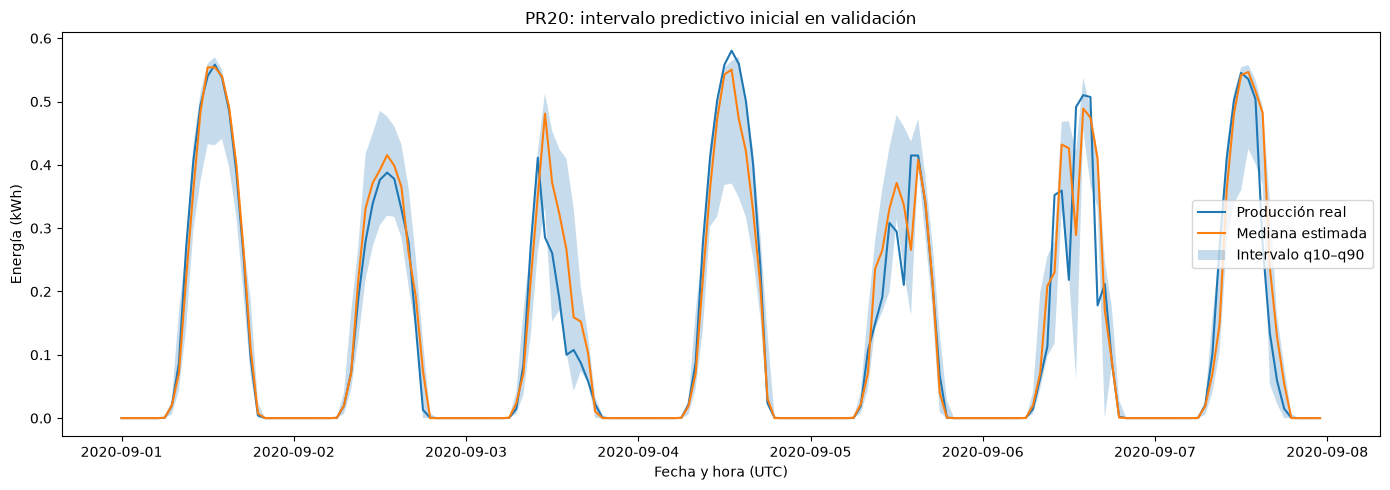

In [100]:
semana = cuantiles_ordenados.loc[
    "2020-09-01":"2020-09-07"
]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(y_val.loc[semana.index], label="Producción real")
ax.plot(semana["q50"], label="Mediana estimada")

ax.fill_between(
    semana.index,
    semana["q10"].to_numpy(),
    semana["q90"].to_numpy(),
    alpha=0.25,
    label="Intervalo q10–q90",
)

ax.set(
    title="PR20: intervalo predictivo inicial en validación",
    xlabel="Fecha y hora (UTC)",
    ylabel="Energía (kWh)",
)

ax.legend()
plt.tight_layout()
plt.show()

In [101]:
resultados_referencia_cuantiles = []

for columna, cuantil in [
    ("q10", 0.10),
    ("q50", 0.50),
    ("q90", 0.90),
]:
    valor_constante = y_train.quantile(cuantil)
    pred_constante = np.full(len(y_val), valor_constante)

    resultados_referencia_cuantiles.append({
        "cuantil": columna,
        "pinball_constante": mean_pinball_loss(
            y_val,
            pred_constante,
            alpha=cuantil,
        ),
        "pinball_modelo": mean_pinball_loss(
            y_val,
            cuantiles_ordenados[columna],
            alpha=cuantil,
        ),
    })

display(
    pd.DataFrame(resultados_referencia_cuantiles).set_index("cuantil")
)

,pinball_constante,pinball_modelo
cuantil,,
q10,0.013119,0.007312
q50,0.065722,0.014496
q90,0.040584,0.006135


### Conclusión de la primera aproximación probabilística

Los cuantiles condicionados al histórico y al calendario mejoran
la pinball loss frente a cuantiles constantes obtenidos únicamente
con entrenamiento.

Sin embargo, los modelos presentan cruces y problemas de calibración.
La ordenación posterior elimina los cruces, pero el intervalo nominal
del 80 % alcanza una cobertura del 46,73 % en validación.

Por tanto, los modelos aportan información predictiva, aunque esta
primera versión no proporciona todavía intervalos bien calibrados.
El conjunto de test permanece reservado.

In [102]:
from sklearn.base import clone

X_desarrollo = pd.concat([X_train, X_val]).sort_index()
y_desarrollo = pd.concat([y_train, y_val]).sort_index()

modelos_finales = {
    "Regresión lineal": clone(modelo_lineal),
    "Random Forest": clone(modelo_rf_optimizado),
    "Gradient Boosting": clone(modelo_gb),
}

for nombre, modelo in modelos_finales.items():
    modelo.fit(X_desarrollo, y_desarrollo)
    print(f"{nombre}: entrenado con {len(X_desarrollo)} filas")

Regresión lineal: entrenado con 7233 filas
Random Forest: entrenado con 7233 filas
Gradient Boosting: entrenado con 7233 filas


In [103]:
X_test = df_test[variables_entrada].copy()
y_test = df_test[variable_objetivo].copy()

predicciones_test = pd.DataFrame(index=y_test.index)
predicciones_test["real"] = y_test

predicciones_test["Persistencia"] = X_test["energia_anterior_1h"]
predicciones_test["Persistencia diaria"] = X_test["energia_anterior_24h"]

for nombre, modelo in modelos_finales.items():
    predicciones_test[nombre] = np.maximum(
        modelo.predict(X_test),
        0,
    )

resultados_test = []

for nombre in predicciones_test.columns.drop("real"):
    resultados_test.append({
        "modelo": nombre,
        "MAE_kwh": mean_absolute_error(
            y_test, predicciones_test[nombre]
        ),
        "RMSE_kwh": np.sqrt(mean_squared_error(
            y_test, predicciones_test[nombre]
        )),
    })

df_resultados_test = pd.DataFrame(
    resultados_test
).set_index("modelo")

display(df_resultados_test)

,MAE_kwh,RMSE_kwh
modelo,,
Persistencia,0.044484,0.084306
Persistencia diaria,0.055667,0.119974
Regresión lineal,0.037846,0.067675
Random Forest,0.027413,0.057113
Gradient Boosting,0.028176,0.058257


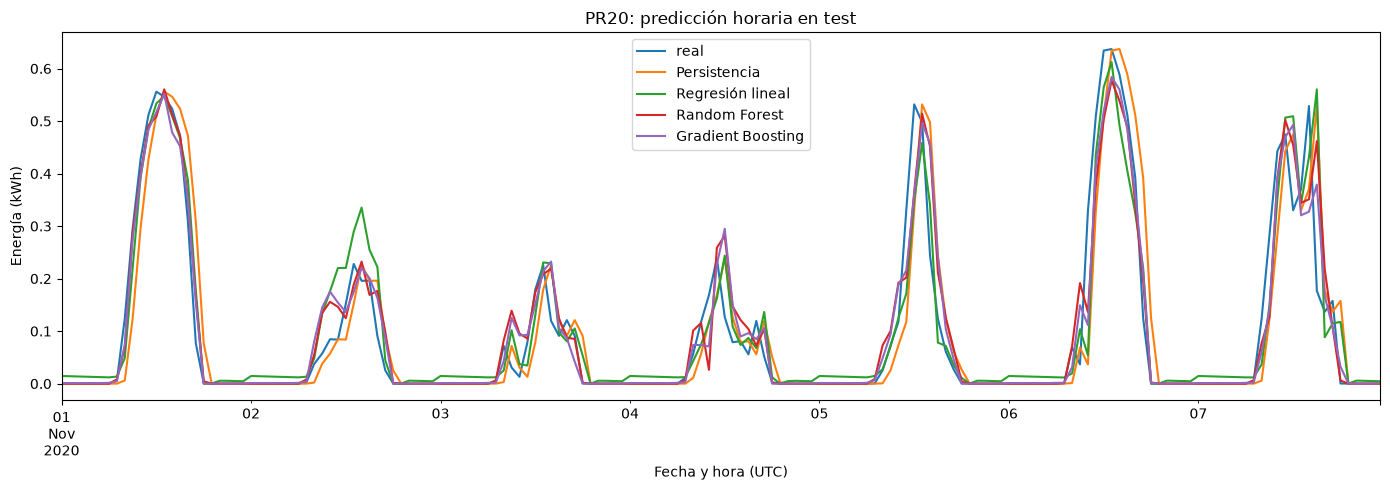

In [104]:
predicciones_test.loc[
    "2020-11-01":"2020-11-07",
    [
        "real",
        "Persistencia",
        "Regresión lineal",
        "Random Forest",
        "Gradient Boosting",
    ],
].plot(
    figsize=(14, 5),
    title="PR20: predicción horaria en test",
    xlabel="Fecha y hora (UTC)",
    ylabel="Energía (kWh)",
)

plt.tight_layout()
plt.show()

In [106]:
modelos_cuantiles_finales = {
    0.10: clone(modelo_q10_alternativo),
    0.50: clone(modelos_cuantiles[0.50]),
    0.90: clone(modelos_cuantiles[0.90]),
}

cuantiles_test_originales = pd.DataFrame(index=X_test.index)

for cuantil, modelo in modelos_cuantiles_finales.items():
    modelo.fit(X_desarrollo, y_desarrollo)

    cuantiles_test_originales[f"q{int(cuantil * 100)}"] = np.maximum(
        modelo.predict(X_test),
        0,
    )

cuantiles_test = pd.DataFrame(
    np.sort(cuantiles_test_originales.to_numpy(), axis=1),
    index=X_test.index,
    columns=["q10", "q50", "q90"],
)

In [107]:
inferior_test = cuantiles_test["q10"]
superior_test = cuantiles_test["q90"]

dentro_test = (
    (y_test >= inferior_test)
    & (y_test <= superior_test)
)

print(f"Cobertura en test: {dentro_test.mean():.2%}")
print(
    "Anchura media:",
    f"{(superior_test - inferior_test).mean():.6f} kWh",
)
print(f"Por debajo: {(y_test < inferior_test).mean():.2%}")
print(f"Por encima: {(y_test > superior_test).mean():.2%}")

Cobertura en test: 54.11%
Anchura media: 0.075516 kWh
Por debajo: 38.77%
Por encima: 7.12%


In [108]:
resultados_cuantiles_test = []

for columna, cuantil in [
    ("q10", 0.10),
    ("q50", 0.50),
    ("q90", 0.90),
]:
    pred_constante = np.full(
        len(y_test),
        y_desarrollo.quantile(cuantil),
    )

    resultados_cuantiles_test.append({
        "cuantil": columna,
        "pinball_constante": mean_pinball_loss(
            y_test, pred_constante, alpha=cuantil
        ),
        "pinball_modelo": mean_pinball_loss(
            y_test, cuantiles_test[columna], alpha=cuantil
        ),
    })

display(
    pd.DataFrame(resultados_cuantiles_test).set_index("cuantil")
)

,pinball_constante,pinball_modelo
cuantil,,
q10,0.010769,0.006911
q50,0.054472,0.014924
q90,0.042059,0.006958


## Conclusiones del primer experimento

Se ha evaluado la predicción de energía fotovoltaica de la próxima
hora utilizando histórico de producción y calendario.

Las configuraciones se seleccionaron con entrenamiento y validación.
Después se reentrenaron con enero–octubre y se evaluaron en
noviembre–diciembre, manteniendo los modelos fijos durante el test.

### Predicción puntual

Random Forest obtuvo el menor error en test:
- MAE: 0,027413 kWh.
- RMSE: 0,057113 kWh.
- Reducción del MAE frente a persistencia: 38,4 %.

Gradient Boosting obtuvo resultados próximos. El orden entre ambos
cambió respecto a validación, por lo que no se concluye una
superioridad general de una familia.

### Predicción probabilística

Los tres cuantiles mejoraron la pinball loss frente a cuantiles
constantes calculados con los datos de desarrollo.

Sin embargo, el intervalo nominal del 80 % alcanzó una cobertura
del 54,11 %, con una anchura media de 0,075516 kWh.
La principal desviación fue la proporción de observaciones por
debajo del límite inferior: 38,77 %.

La ordenación posterior eliminó los cruces, pero no resolvió
los problemas de calibración.

### Alcance y siguientes pasos

Los resultados corresponden a una instalación y un periodo de test
de dos meses. No demuestran generalización a otros años o instalaciones.

Se conserva este experimento como referencia para estudiar el efecto
de añadir irradiación, ampliar los años y mejorar la estimación
de incertidumbre.